In [1]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("House Price India.csv")

# Dataset information
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Convert Excel serial date
df["Date"] = pd.to_datetime(
    df["Date"],
    unit="D",
    origin="1899-12-30",
    errors="coerce"
)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert numeric columns
for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

# Handle unusual bedroom values
df.loc[
    df["number of bedrooms"] > 10,
    "number of bedrooms"
] = np.nan

# Validate house condition
df.loc[
    ~df["condition of the house"].between(1, 5),
    "condition of the house"
] = np.nan

# Validate house grade
df.loc[
    ~df["grade of the house"].between(1, 13),
    "grade of the house"
] = np.nan

# Save cleaned dataset
df.to_csv(
    "House_Price_India_cleaned.csv",
    index=False
)

# Final results
print("Cleaning Completed!")
print("Final Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14619 entries, 0 to 14618
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     14619 non-null  int64  
 1   Date                                   14619 non-null  int64  
 2   number of bedrooms                     14619 non-null  int64  
 3   number of bathrooms                    14619 non-null  float64
 4   living area                            14619 non-null  int64  
 5   lot area                               14619 non-null  int64  
 6   number of floors                       14619 non-null  float64
 7   waterfront present                     14619 non-null  int64  
 8   number of views                        14619 non-null  int64  
 9   condition of the house                 14619 non-null  int64  
 10  grade of the house                     14619 non-null  int64  
 11  Ar

#2.Exploratory Data Analysis (EDA)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("House_Price_India_cleaned.csv")

# Display first 5 records
print(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Column names
print(df.columns.tolist())

sns.set_style("whitegrid")

           id        Date  number of bedrooms  number of bathrooms  \
0  6762810635  2016-05-01                 4.0                 2.50   
1  6762810998  2016-05-01                 5.0                 2.75   
2  6762812605  2016-05-01                 4.0                 2.50   
3  6762812919  2016-05-01                 3.0                 2.00   
4  6762813105  2016-05-01                 3.0                 2.50   

   living area  lot area  number of floors  waterfront present  \
0         2920      4000               1.5                   0   
1         2910      9480               1.5                   0   
2         3310     42998               2.0                   0   
3         2710      4500               1.5                   0   
4         2600      4750               1.0                   0   

   number of views  condition of the house  ...  Built Year  Renovation Year  \
0                0                     5.0  ...        1909                0   
1                0    

In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Number of Rows: 14619
Number of Columns: 23

Column Names:
Index(['id', 'Date', 'number of bedrooms', 'number of bathrooms',
       'living area', 'lot area', 'number of floors', 'waterfront present',
       'number of views', 'condition of the house', 'grade of the house',
       'Area of the house(excluding basement)', 'Area of the basement',
       'Built Year', 'Renovation Year', 'Postal Code', 'Lattitude',
       'Longitude', 'living_area_renov', 'lot_area_renov',
       'Number of schools nearby', 'Distance from the airport', 'Price'],
      dtype='object')

Data Types:
id                                         int64
Date                                      object
number of bedrooms                       float64
number of bathrooms                      float64
living area                                int64
lot area                                   int64
number of floors                         float64
waterfront present                         int64
number of views          

In [4]:
print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())


Statistical Summary:
                 id  number of bedrooms  number of bathrooms   living area  \
count  1.461900e+04        14617.000000         14619.000000  14619.000000   
mean   6.762821e+09            3.376685             2.129557   2098.156851   
std    6.237162e+03            0.903983             0.769955    928.218740   
min    6.762810e+09            1.000000             0.500000    370.000000   
25%    6.762815e+09            3.000000             1.750000   1440.000000   
50%    6.762821e+09            3.000000             2.250000   1930.000000   
75%    6.762826e+09            4.000000             2.500000   2570.000000   
max    6.762832e+09           10.000000             8.000000  13540.000000   

           lot area  number of floors  waterfront present  number of views  \
count  1.461900e+04      14619.000000        14619.000000     14619.000000   
mean   1.509369e+04          1.502326            0.007661         0.232848   
std    3.792089e+04          0.540241    

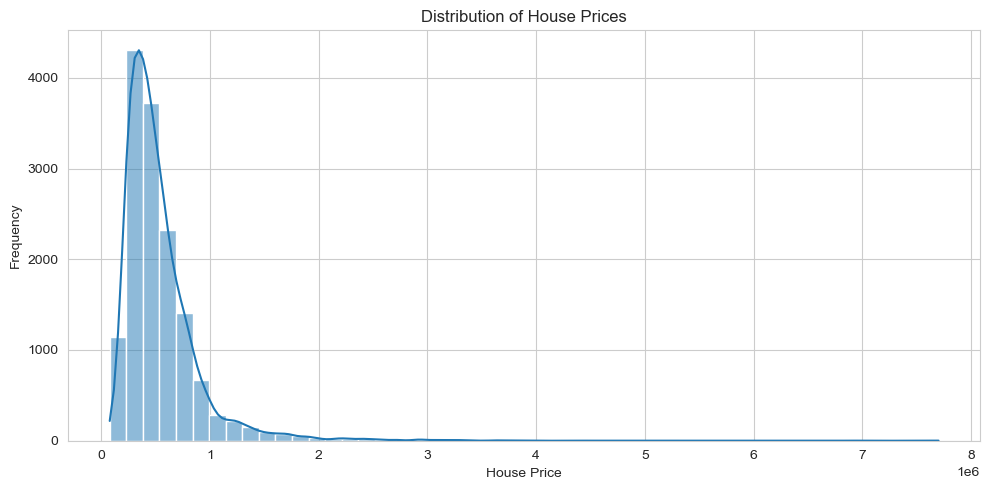

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Price"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

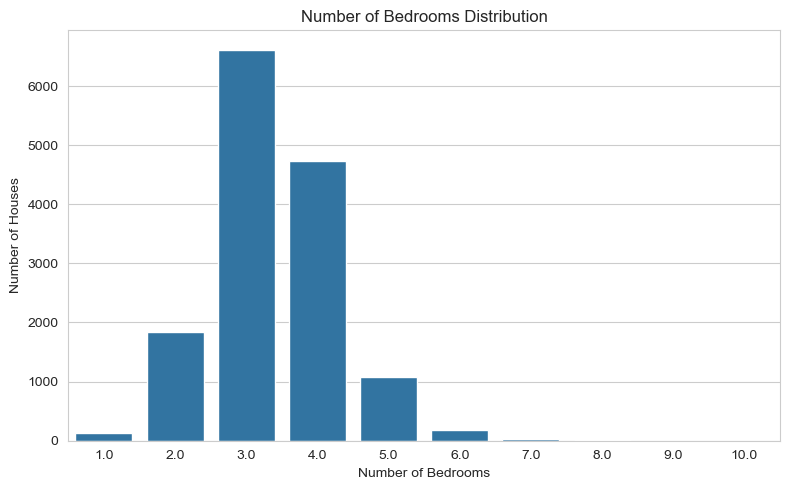

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="number of bedrooms"
)

plt.title("Number of Bedrooms Distribution")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

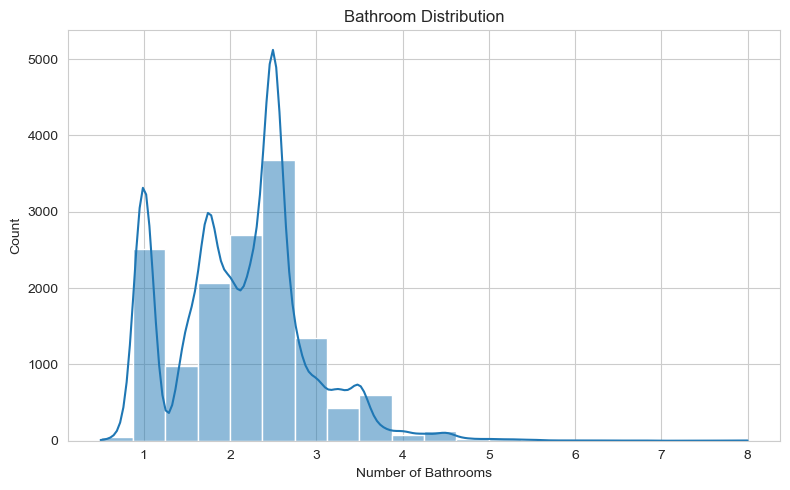

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["number of bathrooms"].dropna(),
    bins=20,
    kde=True
)

plt.title("Bathroom Distribution")
plt.xlabel("Number of Bathrooms")

plt.tight_layout()
plt.show()

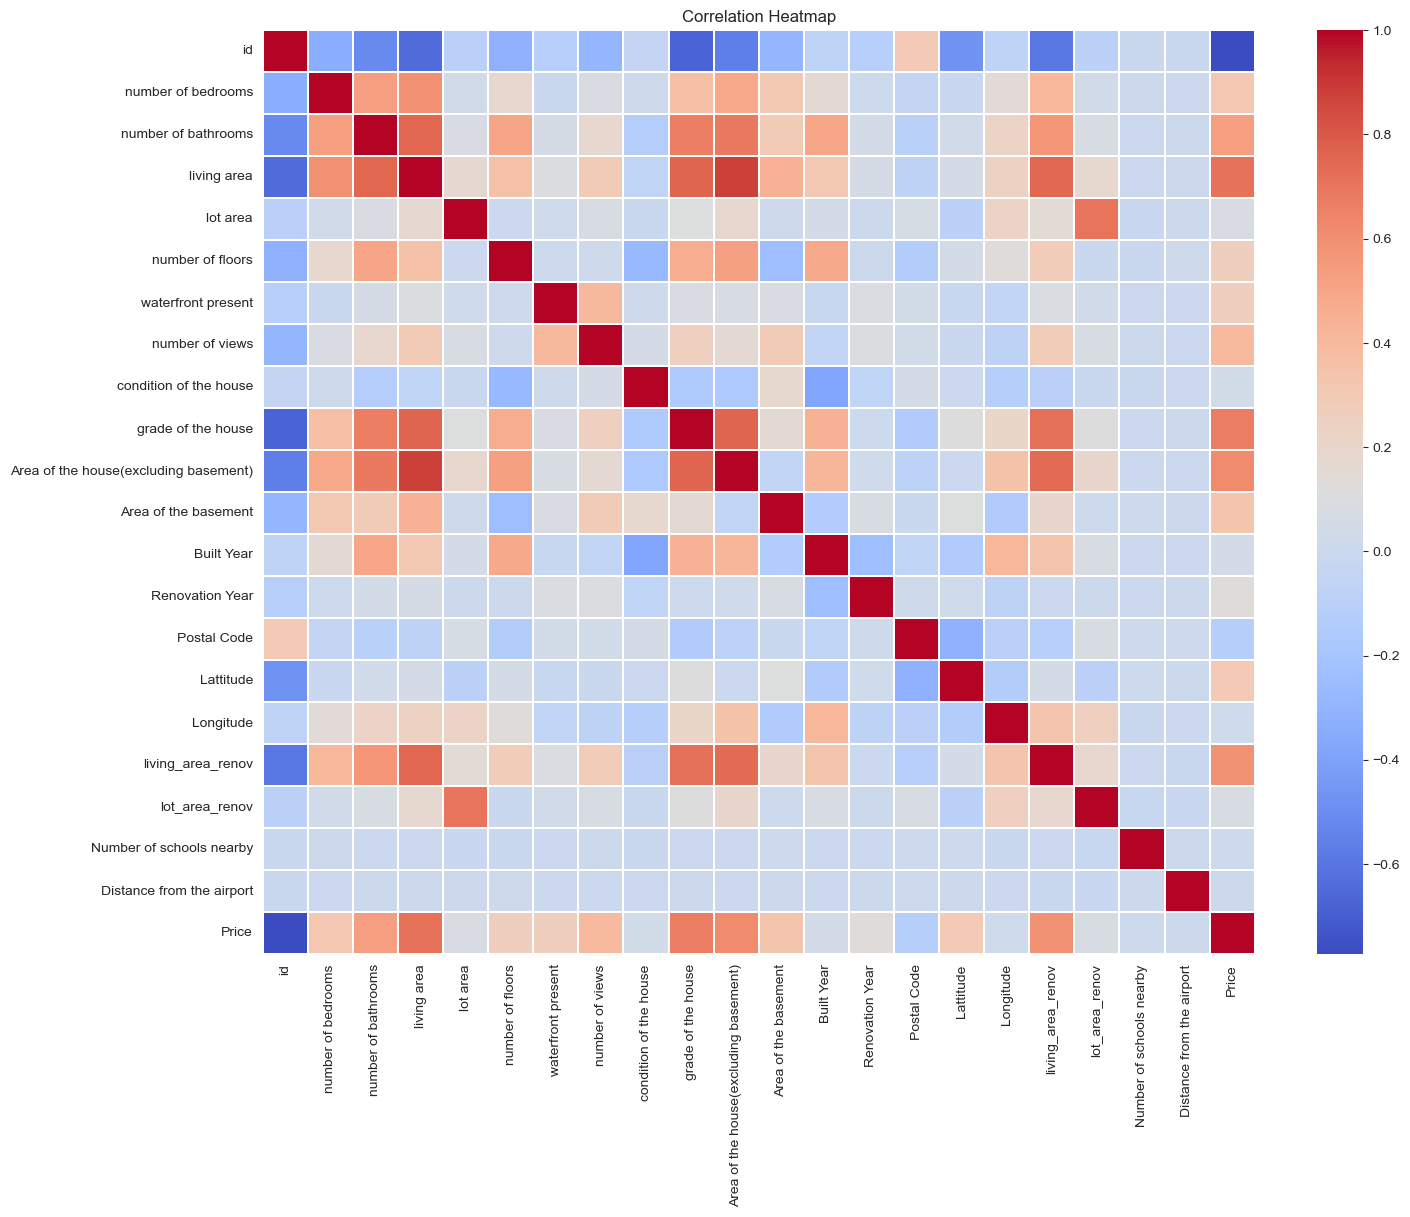

Price                                    1.000000
living area                              0.712276
grade of the house                       0.671805
Area of the house(excluding basement)    0.615179
living_area_renov                        0.585021
number of bathrooms                      0.532031
number of views                          0.394954
Area of the basement                     0.330499
number of bedrooms                       0.319419
Lattitude                                0.297570
waterfront present                       0.263943
number of floors                         0.262649
Renovation Year                          0.133362
lot area                                 0.082117
lot_area_renov                           0.075697
Built Year                               0.050936
condition of the house                   0.040609
Longitude                                0.024807
Number of schools nearby                 0.009904
Distance from the airport                0.004074


<Figure size 640x480 with 0 Axes>

In [11]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 12))
correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap")
plt.show()
plt.savefig("correlation heatmap", dpi=300)

# Correlation with Price
print(
    correlation["Price"]
    .sort_values(ascending=False)
)


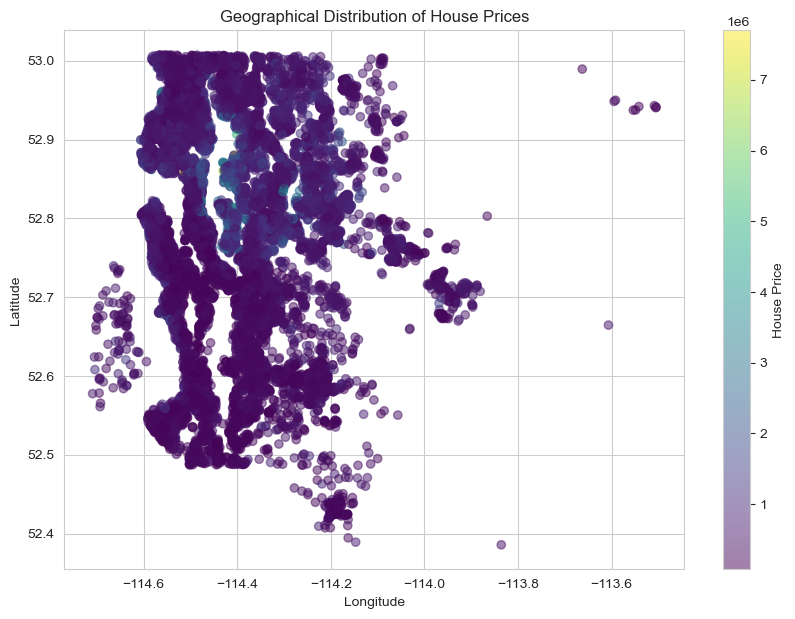

<Figure size 640x480 with 0 Axes>

In [10]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df["Longitude"],
    df["Lattitude"],
    c=df["Price"],
    cmap="viridis",
    alpha=0.5
)

plt.colorbar(scatter, label="House Price")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of House Prices")
plt.show()
plt.savefig("geographical distribution of house prices",dpi=300)

In [12]:
plt.savefig("plot_name.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

#3.Prediction Models

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

df = pd.read_csv("House_Price_India_cleaned.csv")

print(df.head())
print(df.shape)

           id        Date  number of bedrooms  number of bathrooms  \
0  6762810635  2016-05-01                 4.0                 2.50   
1  6762810998  2016-05-01                 5.0                 2.75   
2  6762812605  2016-05-01                 4.0                 2.50   
3  6762812919  2016-05-01                 3.0                 2.00   
4  6762813105  2016-05-01                 3.0                 2.50   

   living area  lot area  number of floors  waterfront present  \
0         2920      4000               1.5                   0   
1         2910      9480               1.5                   0   
2         3310     42998               2.0                   0   
3         2710      4500               1.5                   0   
4         2600      4750               1.0                   0   

   number of views  condition of the house  ...  Built Year  Renovation Year  \
0                0                     5.0  ...        1909                0   
1                0    

In [15]:
# Convert Date into datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Extract useful date information
df["Sale_Year"] = df["Date"].dt.year
df["Sale_Month"] = df["Date"].dt.month

# Remove rows where target is missing
df = df.dropna(subset=["Price"])

# Remove identifier and original date
df = df.drop(columns=["id", "Date"], errors="ignore")

# Separate features and target
X = df.drop(columns=["Price"])
y = df["Price"]

# Treat Postal Code as categorical
if "Postal Code" in X.columns:
    X["Postal Code"] = X["Postal Code"].astype("string")

print("Features:", X.shape)
print("Target:", y.shape)


Features: (14619, 22)
Target: (14619,)


In [16]:

# Recreate the date information for splitting
split_df = pd.read_csv("House_Price_India_cleaned.csv")
split_df["Date"] = pd.to_datetime(split_df["Date"], errors="coerce")

if split_df["Date"].notna().sum() > 0 and split_df["Date"].nunique() >= 2:
    # Use the earliest 80% of dates for training
    unique_dates = np.sort(split_df["Date"].dropna().unique())
    cutoff = unique_dates[int(len(unique_dates) * 0.8)]

    train_mask = split_df["Date"] < cutoff
    test_mask = split_df["Date"] >= cutoff

    # Keep only rows with valid dates and target values
    valid_mask = split_df["Date"].notna() & split_df["Price"].notna()

    train_mask = train_mask & valid_mask
    test_mask = test_mask & valid_mask

    X_train = X.loc[train_mask].copy()
    X_test = X.loc[test_mask].copy()
    y_train = y.loc[train_mask]
    y_test = y.loc[test_mask]

else:
    # Fallback if there are not enough usable dates
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 12128
Testing records: 2491


In [17]:

from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


In [18]:

from sklearn.ensemble import GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print(name, "completed")

results_df = pd.DataFrame(results)
print(results_df.sort_values("RMSE"))

Linear Regression completed
Ridge Regression completed
Decision Tree completed
Random Forest completed
Extra Trees completed
Gradient Boosting completed
               Model           MAE           RMSE  R2 Score
4        Extra Trees  66542.958664  115280.589745  0.899577
3      Random Forest  70458.017352  128440.425545  0.875341
5  Gradient Boosting  84701.973967  138706.921559  0.854616
1   Ridge Regression  97153.387873  154643.676983  0.819289
0  Linear Regression  97131.385593  154708.504596  0.819138
2      Decision Tree  96184.063793  194530.367468  0.714047


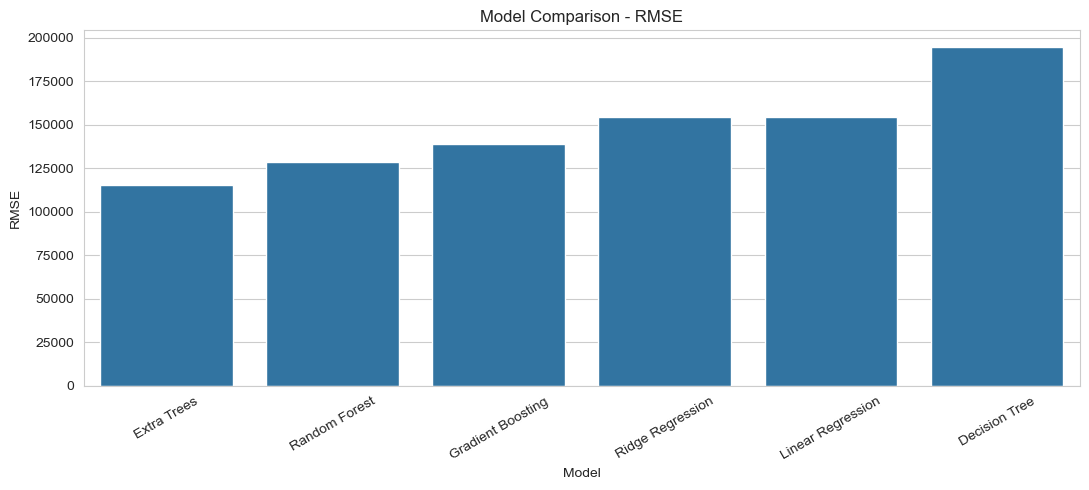

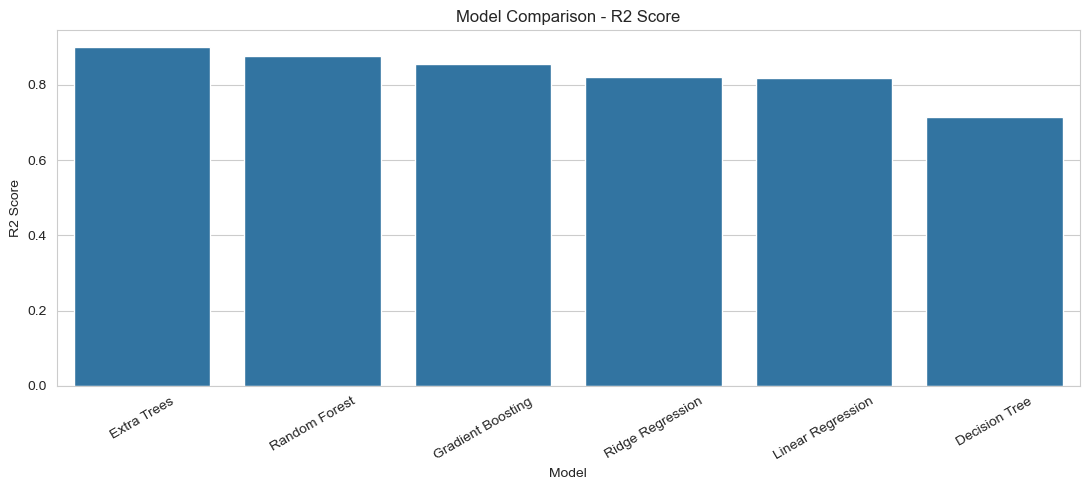

In [19]:

# Compare RMSE
plt.figure(figsize=(11, 5))

sns.barplot(
    data=results_df.sort_values("RMSE"),
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Compare R2 scores
plt.figure(figsize=(11, 5))

sns.barplot(
    data=results_df.sort_values("R2 Score", ascending=False),
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison - R2 Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [20]:

best_model_name = results_df.sort_values("RMSE").iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print(
    results_df[results_df["Model"] == best_model_name]
)


Best Model: Extra Trees
         Model           MAE           RMSE  R2 Score
4  Extra Trees  66542.958664  115280.589745  0.899577


   Actual Price  Predicted Price
0       2000000     1.385110e+06
1       1570000     1.468075e+06
2       1390000     1.284965e+06
3       1260000     1.276799e+06
4       1250000     1.285092e+06
5       1240000     1.002553e+06
6       1200000     9.325376e+05
7       1150000     1.044364e+06
8       1080000     8.826868e+05
9       1030000     8.511496e+05


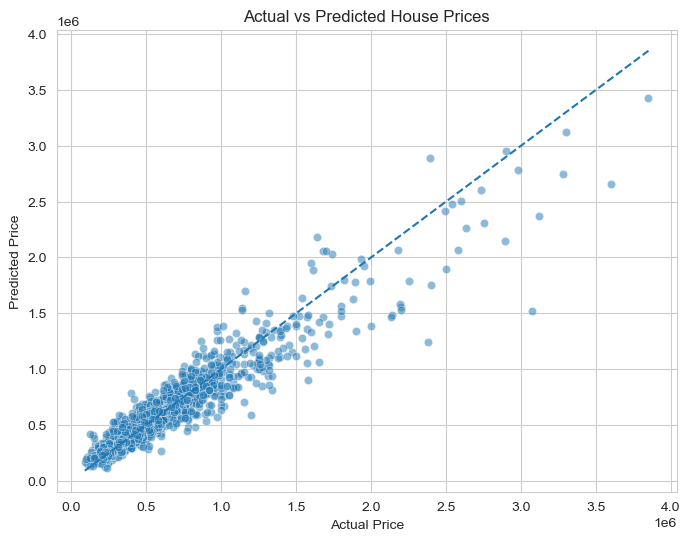

In [21]:

best_predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": best_predictions
})

print(comparison.head(10))

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=comparison,
    x="Actual Price",
    y="Predicted Price",
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(
    comparison["Actual Price"].min(),
    comparison["Predicted Price"].min()
)

max_value = max(
    comparison["Actual Price"].max(),
    comparison["Predicted Price"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.show()


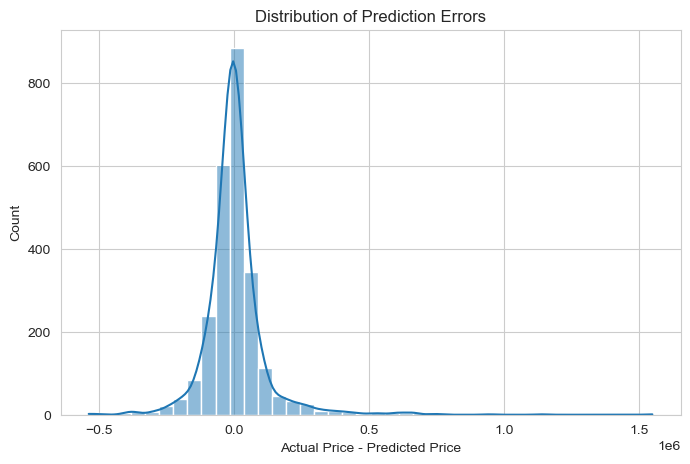

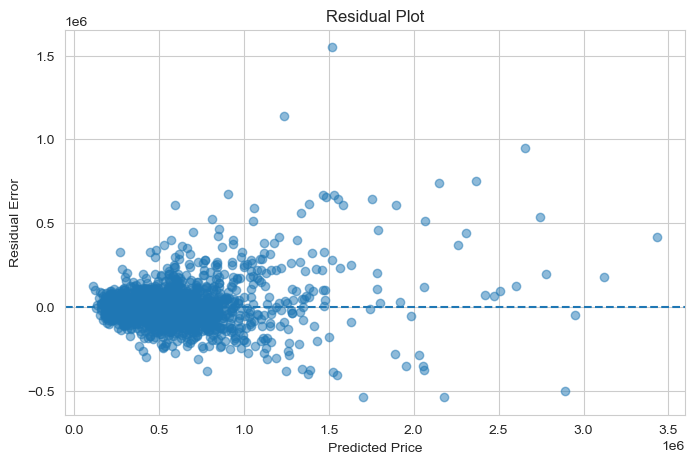

In [22]:

residuals = y_test.values - best_predictions

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Price - Predicted Price")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual Error")
plt.title("Residual Plot")
plt.show()


In [23]:

import joblib

joblib.dump(best_model, "best_house_price_model.pkl")

print("Best model saved successfully!")


Best model saved successfully!


In [24]:

# Select one house from the test dataset
new_house = X_test.iloc[[0]]

# Predict its price
predicted_price = best_model.predict(new_house)

print("Predicted House Price:", predicted_price[0])
print("Actual House Price:", y_test.iloc[0])


Predicted House Price: 1385109.6223968253
Actual House Price: 2000000


#4.Dashboard Creation

In [25]:

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# -----------------------------
# 1. Page configuration
# -----------------------------
st.set_page_config(
    page_title="House Price Prediction",
    page_icon="🏠",
    layout="wide"
)

st.title("🏠 House Price Prediction Dashboard")
st.write(
    "Explore housing data, compare model performance, "
    "and estimate house prices using machine learning."
)

# -----------------------------
# 2. Load dataset and model
# -----------------------------
@st.cache_data
def load_data():
    data = pd.read_csv("House_Price_India_cleaned.csv")
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    return data

@st.cache_resource
def load_model():
    return joblib.load("best_house_price_model.pkl")

try:
    df = load_data()
    model = load_model()
except FileNotFoundError as error:
    st.error(f"Required file not found: {error}")
    st.stop()

# -----------------------------
# 3. Prepare dashboard data
# -----------------------------
df["Sale Year"] = df["Date"].dt.year
df["Sale Month"] = df["Date"].dt.month

# -----------------------------
# 4. Sidebar navigation
# -----------------------------
page = st.sidebar.radio(
    "Dashboard Navigation",
    [
        "Overview",
        "Data Visualization",
        "Model Performance",
        "Price Prediction"
    ]
)

# -----------------------------
# 5. Overview page
# -----------------------------
if page == "Overview":

    st.header("Dataset Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total Houses", f"{len(df):,}")
    col2.metric("Average Price", f"{df['Price'].mean():,.0f}")
    col3.metric("Minimum Price", f"{df['Price'].min():,.0f}")
    col4.metric("Maximum Price", f"{df['Price'].max():,.0f}")

    st.subheader("Dataset Preview")
    st.dataframe(df.head(20), use_container_width=True)

    st.subheader("Dataset Information")
    st.write("Number of rows:", df.shape[0])
    st.write("Number of columns:", df.shape[1])
    st.write("Missing values:", int(df.isna().sum().sum()))

# -----------------------------
# 6. Data visualization page
# -----------------------------
elif page == "Data Visualization":

    st.header("House Price Data Visualization")

    st.subheader("House Price Distribution")

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(df["Price"].dropna(), bins=40, kde=True, ax=ax)
    ax.set_xlabel("House Price")
    ax.set_title("Distribution of House Prices")
    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Price vs Living Area")

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.scatterplot(
        data=df,
        x="living area",
        y="Price",
        alpha=0.4,
        ax=ax
    )
    ax.set_title("House Price vs Living Area")
    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Price by House Grade")

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(
        data=df,
        x="grade of the house",
        y="Price",
        ax=ax
    )
    ax.set_title("House Price by Grade")
    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Correlation Heatmap")

    numeric_df = df.select_dtypes(include=np.number)

    fig, ax = plt.subplots(figsize=(14, 9))
    sns.heatmap(
        numeric_df.corr(),
        cmap="coolwarm",
        ax=ax
    )
    ax.set_title("Feature Correlation Heatmap")
    st.pyplot(fig)
    plt.close(fig)

# -----------------------------
# 7. Model performance page
# -----------------------------
elif page == "Model Performance":

    st.header("Machine Learning Model Performance")

    results_path = Path("results.csv")

    if results_path.exists():

        results_df = pd.read_csv(results_path)

        st.dataframe(results_df, use_container_width=True)

        if "RMSE" in results_df.columns:
            st.subheader("Model Comparison - RMSE")

            fig, ax = plt.subplots(figsize=(10, 5))
            sns.barplot(
                data=results_df.sort_values("RMSE"),
                x="Model",
                y="RMSE",
                ax=ax
            )
            ax.tick_params(axis="x", rotation=30)
            st.pyplot(fig)
            plt.close(fig)

        if "R2 Score" in results_df.columns:
            st.subheader("Model Comparison - R² Score")

            fig, ax = plt.subplots(figsize=(10, 5))
            sns.barplot(
                data=results_df.sort_values(
                    "R2 Score",
                    ascending=False
                ),
                x="Model",
                y="R2 Score",
                ax=ax
            )
            ax.tick_params(axis="x", rotation=30)
            st.pyplot(fig)
            plt.close(fig)

    else:
        st.info(
            "No results.csv found. Save your model comparison "
            "DataFrame as results.csv to display model metrics."
        )

    st.caption(
        "The prediction model loaded by this dashboard is "
        "best_house_price_model.pkl."
    )

# -----------------------------
# 8. House price prediction page
# -----------------------------
elif page == "Price Prediction":

    st.header("Predict House Price")

    # Recreate the exact feature columns used during training
    X_reference = df.drop(
        columns=["id", "Date", "Price"],
        errors="ignore"
    ).copy()

    X_reference["Sale_Year"] = df["Date"].dt.year
    X_reference["Sale_Month"] = df["Date"].dt.month

    if "Postal Code" in X_reference.columns:
        X_reference["Postal Code"] = (
            X_reference["Postal Code"].astype("string")
        )

    st.write("Enter the house details below:")

    user_input = {}

    with st.form("prediction_form"):

        for column in X_reference.columns:

            series = X_reference[column]

            if (
                pd.api.types.is_object_dtype(series)
                or isinstance(series.dtype, pd.StringDtype)
                or isinstance(series.dtype, pd.CategoricalDtype)
            ):
                choices = sorted(
                    series.dropna().astype(str).unique().tolist()
                )

                if choices:
                    user_input[column] = st.selectbox(
                        column,
                        choices
                    )
                else:
                    user_input[column] = st.text_input(column, "")

            else:
                median_value = series.median()

                if pd.isna(median_value):
                    median_value = 0.0

                user_input[column] = st.number_input(
                    column,
                    value=float(median_value),
                    step=1.0
                )

        submitted = st.form_submit_button("Predict House Price")

    if submitted:

        input_df = pd.DataFrame(
            [user_input],
            columns=X_reference.columns
        )

        if "Postal Code" in input_df.columns:
            input_df["Postal Code"] = (
                input_df["Postal Code"].astype("string")
            )

        try:
            prediction = model.predict(input_df)[0]

            st.success("Prediction completed!")

            st.metric(
                "Estimated House Price",
                f"{prediction:,.2f}"
            )

            st.caption(
                "This is a machine learning estimate, not a "
                "guaranteed market valuation."
            )

        except Exception as error:
            st.error(f"Prediction failed: {error}")


2026-11-02 15:46:09.669 
  command:

    streamlit run C:\Users\91630\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-02 15:46:09.669 No runtime found, using MemoryCacheStorageManager
2026-11-02 15:46:09.669 No runtime found, using MemoryCacheStorageManager
2026-11-02 15:46:09.885 Session state does not function when running a script without `streamlit run`


In [26]:
results_df.to_csv("results.csv", index=False)